<a href="https://colab.research.google.com/github/ReemasTariq/NLP/blob/main/Lab_11_Attention_with_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [4]:
import pandas as pd
import glob

csv_files = glob.glob('/content/Lab_11_QnA_Dataset*.csv')

if not csv_files:
    raise FileNotFoundError("Dataset not found. Please upload the CSV file.")

csv_path = csv_files[0]
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Number of questions:", len(df))
print(df.head())


Dataset loaded successfully!
Number of questions: 168
               question  answer_id                answer
0      Do you get hurt?          0  I don't have a body.
1  Do you have fingers?          0  I don't have a body.
2   Do you ever breathe          0  I don't have a body.
3     Do you masticate?          0  I don't have a body.
4     Can you throw up?          0  I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [6]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df['answer_id'].nunique())

    def forward(self, x):
        hidden, _ = self.rnn(self.emb(x))
        scores = self.att(hidden).squeeze(-1)
        scores = scores.masked_fill(x == 0, -1e9)  # ignore padding
        weights = torch.softmax(scores, dim=1)
        context = (hidden * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

# Map answer labels to 0..C-1 for cross entropy.
answer_labels = sorted(df['answer_id'].unique())
answer_to_index = {label: i for i, label in enumerate(answer_labels)}
y = torch.tensor([answer_to_index[label] for label in df['answer_id']], dtype=torch.long)
model = RNN()


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
model.train()
for epoch in range(50):
    optimizer.zero_grad()  # clear gradients from previous epoch
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
print(f'Training finished! Final loss: {loss.item():.4f}')
model.eval()


Training finished! Final loss: 0.0688


RNN(
  (emb): Embedding(227, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)

## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

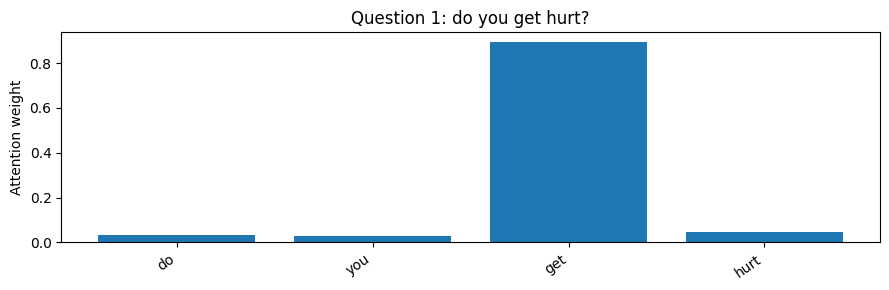

Highest attention: get (0.8931)


In [8]:
# Use tokenizer's exact tokens so labels match the model inputs.
def show_attention(index, ax=None):
    import numpy as np
    token_ids = X[index][X[index] != 0].tolist()
    words = tokenizer.sequences_to_texts([token_ids])[0].split()
    with torch.no_grad():
        logits, weights = model(X[index:index+1])
    values = weights[0, :len(words)].cpu().numpy()
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 3))
    ax.bar(range(len(words)), values)
    ax.set_xticks(range(len(words)), words, rotation=35, ha='right')
    ax.set_ylabel('Attention weight')
    ax.set_title(f'Question {index + 1}: {df.iloc[index]["question"]}')
    highest = words[int(np.argmax(values))]
    return highest, float(max(values))

word, weight = show_attention(0)
plt.tight_layout()
plt.show()
print(f'Highest attention: {word} ({weight:.4f})')


## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

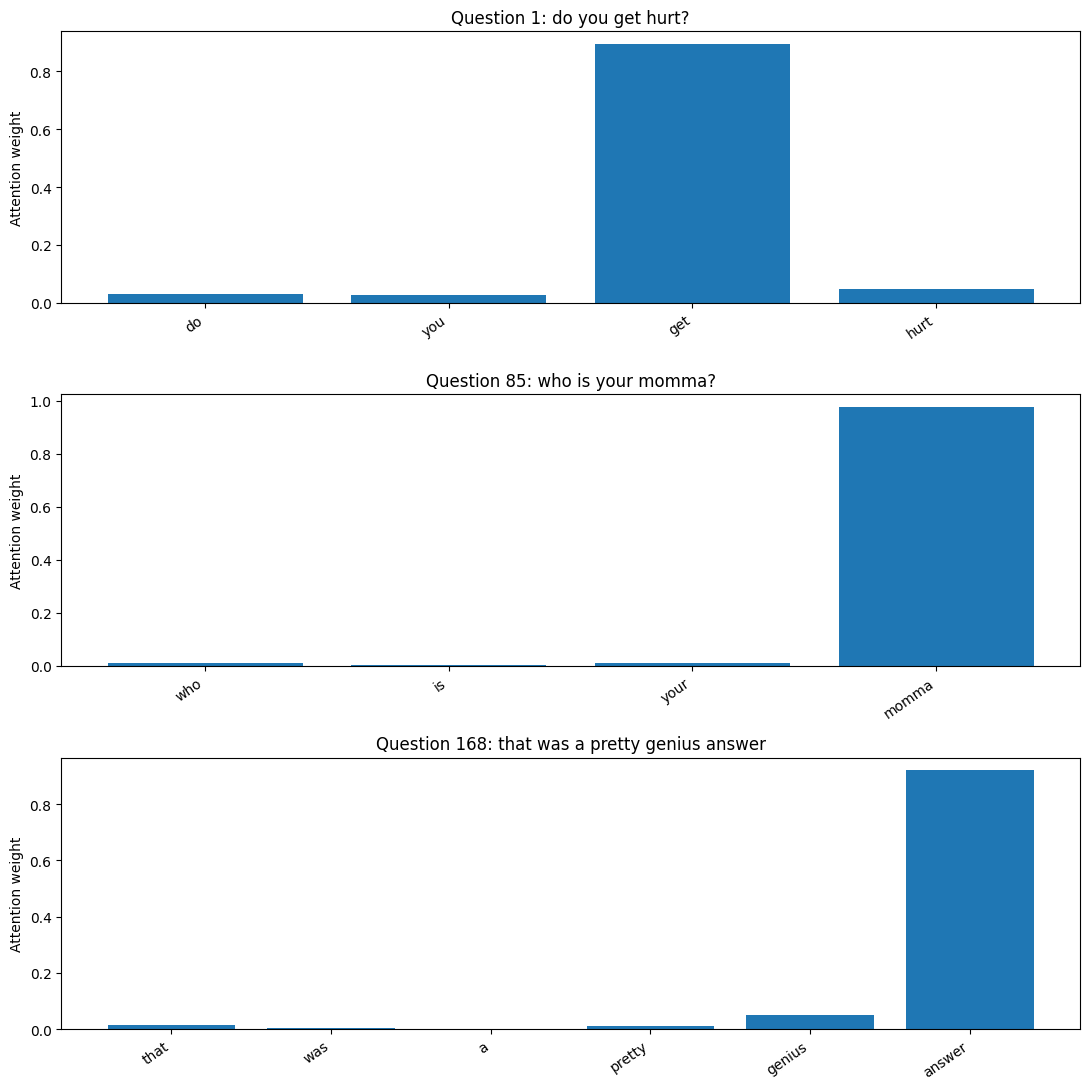

,Question,Highest attention word,Attention weight
0,do you get hurt?,get,0.8931
1,who is your momma?,momma,0.9758
2,that was a pretty genius answer,answer,0.9203


In [9]:
# Task 1: three different questions and their highest-attention words
if len(df) < 3:
    raise ValueError('Task 1 requires at least three questions.')
selected_indices = [0, len(df)//2, len(df)-1]
fig, axes = plt.subplots(3, 1, figsize=(11, 11))
results_task1 = []
for idx, ax in zip(selected_indices, axes):
    word, weight = show_attention(idx, ax)
    results_task1.append({'Question': df.iloc[idx]['question'],
                          'Highest attention word': word,
                          'Attention weight': round(weight, 4)})
plt.tight_layout()
plt.show()
display(pd.DataFrame(results_task1))


**Task 1 — Answer:** The table identifies the highest-attention word for each of the three questions. Compare these words with the meanings of the corresponding questions: a content word related to the main topic may be useful, while a common word may not be. High attention indicates what this trained model emphasizes, not proof that the word is objectively important. The conclusion must be based on the displayed results.


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question 1: are you old?
Question 2: how old are you?
Shared answer_id: 1


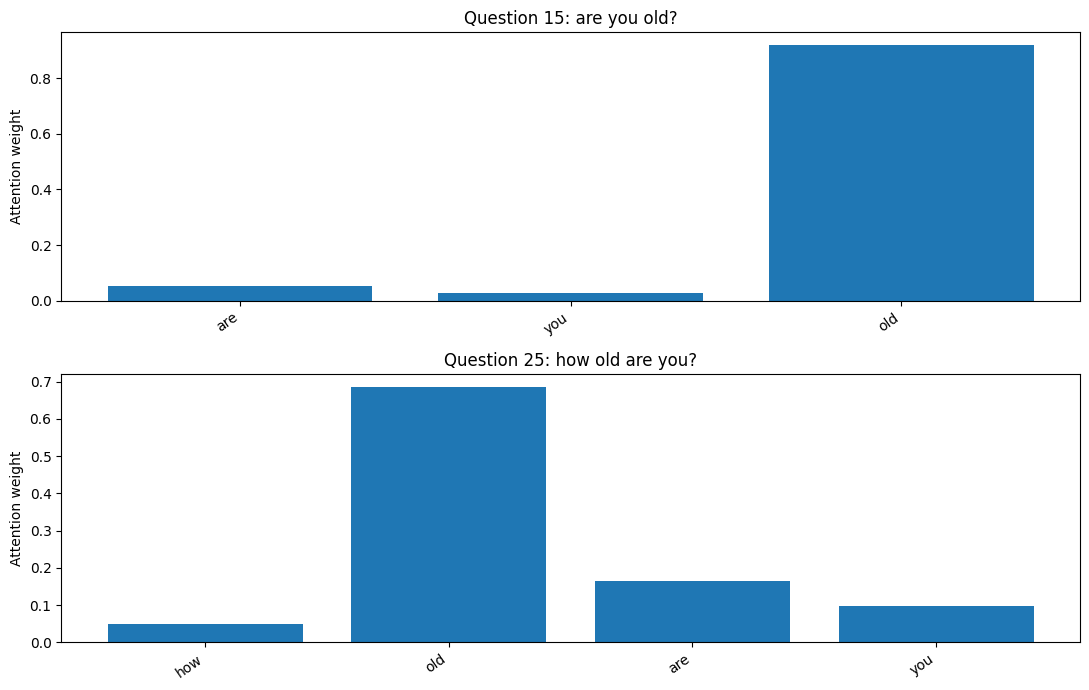

Question 1 highest-attention word: old (0.9187)
Question 2 highest-attention word: old (0.6867)
Comparison: Same highest-attention word
Interpretation: Attention can emphasize different words in differently phrased questions, even when both belong to the same answer group. Interpret the specific words above in context.


In [10]:
# Task 2: automatically suggest a pair with overlapping vocabulary but different wording.
# Inspect the displayed pair to verify that its meaning is actually similar.
from itertools import combinations
from collections import Counter

texts = df['question'].astype(str).tolist()
stopwords = {'what','is','are','the','a','an','of','to','in','on','for','and','how','do','does','can','you','which','why','it'}
def keywords(text):
    seq = tokenizer.texts_to_sequences([text])[0]
    words = tokenizer.sequences_to_texts([seq])[0].split()
    return set(words) - stopwords

# Prefer questions from the same answer group, since they likely express similar intent.
pairs = []
for group, indices in df.groupby('answer_id').groups.items():
    indices = list(indices)
    for i, j in combinations(indices, 2):
        if texts[i] == texts[j]:
            continue
        a, b = keywords(texts[i]), keywords(texts[j])
        similarity = len(a & b) / max(len(a | b), 1)
        pairs.append((similarity, i, j))
if not pairs:
    raise ValueError('No differently worded questions with the same answer_id were found. Select a semantically similar pair manually.')
_, i, j = max(pairs)
print('Question 1:', texts[i])
print('Question 2:', texts[j])
print('Shared answer_id:', df.iloc[i]['answer_id'])
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
first_word, first_weight = show_attention(i, axes[0])
second_word, second_weight = show_attention(j, axes[1])
plt.tight_layout()
plt.show()
print(f'Question 1 highest-attention word: {first_word} ({first_weight:.4f})')
print(f'Question 2 highest-attention word: {second_word} ({second_weight:.4f})')
print('Comparison:', 'Same highest-attention word' if first_word == second_word else 'Different highest-attention words')
print('Interpretation: Attention can emphasize different words in differently phrased questions, even when both belong to the same answer group. Interpret the specific words above in context.')


**Task 2 — Answer:** The two questions were selected from the same `answer_id` group and use different wording. The charts and printed output reveal whether the model emphasizes the same or different words. If the highest-attention words differ, the model may be using different lexical cues for similar intents. If they match, it may have learned a common cue. Attention is context-dependent and does not by itself prove semantic understanding. **Check that the selected pair genuinely has similar meaning before submission**; sharing an answer group is a useful heuristic, not a guarantee.
